# 01 · Data Understanding

**Goal:** load the raw UCI Beijing PM2.5 file and understand its size, columns, missing values and how PM2.5 is distributed.

Dataset: hourly readings from the US Embassy in Beijing, 1 Jan 2010 to 31 Dec 2014.

In [1]:
import os
import sys

# Find the project folder (the one that contains config.py) and work from there
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "config.py")):
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config

FIG = "reports/figures"
OUT = "data/GeneratedOutput/01.EDA"
os.makedirs(FIG, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Load the raw data

In [2]:
from data_loader import load_raw_data

raw = load_raw_data(config.RAW_FILE)
print("Rows:", raw.shape[0], "| Columns:", raw.shape[1])
print("From", raw.index.min(), "to", raw.index.max())
raw.head()

Rows: 43824 | Columns: 8
From 2010-01-01 00:00:00 to 2014-12-31 23:00:00


,pm25,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
datetime,,,,,,,,
2010-01-01 00:00:00,NaN,-21,-11.0,1021.0,NW,1.79,0,0
2010-01-01 01:00:00,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2010-01-01 02:00:00,NaN,-21,-11.0,1019.0,NW,6.71,0,0
2010-01-01 03:00:00,NaN,-21,-14.0,1019.0,NW,9.84,0,0
2010-01-01 04:00:00,NaN,-20,-12.0,1018.0,NW,12.97,0,0


## 2. What each column means

| Column | Meaning | Unit |
| --- | --- | --- |
| `pm25` | PM2.5 concentration (our target) | µg/m³ |
| `DEWP` | Dew point | °C |
| `TEMP` | Temperature | °C |
| `PRES` | Air pressure | hPa |
| `cbwd` | Combined wind direction (NE, NW, SE, cv = calm/variable) | text |
| `Iws` | Cumulated wind speed | m/s |
| `Is` | Cumulated hours of snow | hours |
| `Ir` | Cumulated hours of rain | hours |

In [3]:
raw.dtypes

pm25    float64
DEWP      int64
TEMP    float64
PRES    float64
cbwd        str
Iws     float64
Is        int64
Ir        int64
dtype: object

## 3. Summary statistics

In [4]:
summary = raw.describe().T.round(2)
summary.to_csv(f"{OUT}/01_dataset_summary.csv")
summary

,count,mean,std,min,25%,50%,75%,max
pm25,41757.0,98.61,92.05,0.00,29.00,72.00,137.00,994.0
DEWP,43824.0,1.82,14.43,-40.00,-10.00,2.00,15.00,28.0
TEMP,43824.0,12.45,12.20,-19.00,2.00,14.00,23.00,42.0
PRES,43824.0,1016.45,10.27,991.00,1008.00,1016.00,1025.00,1046.0
Iws,43824.0,23.89,50.01,0.45,1.79,5.37,21.91,585.6
Is,43824.0,0.05,0.76,0.00,0.00,0.00,0.00,27.0
Ir,43824.0,0.19,1.42,0.00,0.00,0.00,0.00,36.0


## 4. Missing values

In [5]:
missing = pd.DataFrame({
    "missing_hours": raw.isna().sum(),
    "missing_percent": (raw.isna().mean() * 100).round(2),
})
missing.to_csv(f"{OUT}/02_missing_values.csv")
missing

,missing_hours,missing_percent
pm25,2067,4.72
DEWP,0,0.00
TEMP,0,0.00
PRES,0,0.00
cbwd,0,0.00
Iws,0,0.00
Is,0,0.00
Ir,0,0.00


Only PM2.5 has gaps. Let's see **when** they happen.

Longest gap: 155 hours in a row


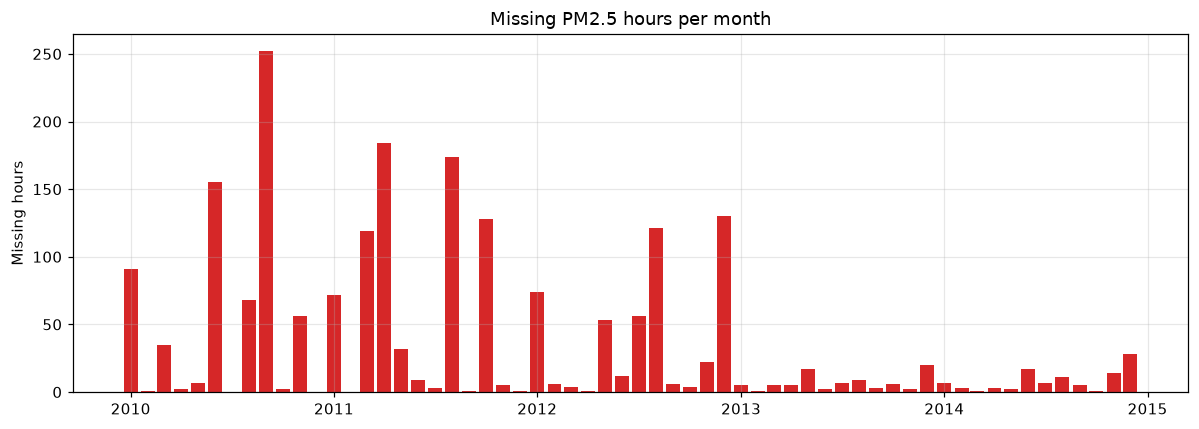

In [6]:
missing_by_month = raw["pm25"].isna().resample("MS").sum()

# Longest run of missing hours in a row
is_missing = raw["pm25"].isna().astype(int)
run_id = (is_missing != is_missing.shift()).cumsum()
longest_gap = is_missing.groupby(run_id).sum().max()
print("Longest gap:", longest_gap, "hours in a row")

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(missing_by_month.index, missing_by_month.values, width=25, color="tab:red")
ax.set_title("Missing PM2.5 hours per month")
ax.set_ylabel("Missing hours")
plt.tight_layout()
plt.savefig(f"{FIG}/01_missing_values.png")
plt.show()

## 5. PM2.5 distribution

Mean: 98.6 | Median: 72.0 | Max: 994.0 | Skew: 1.8


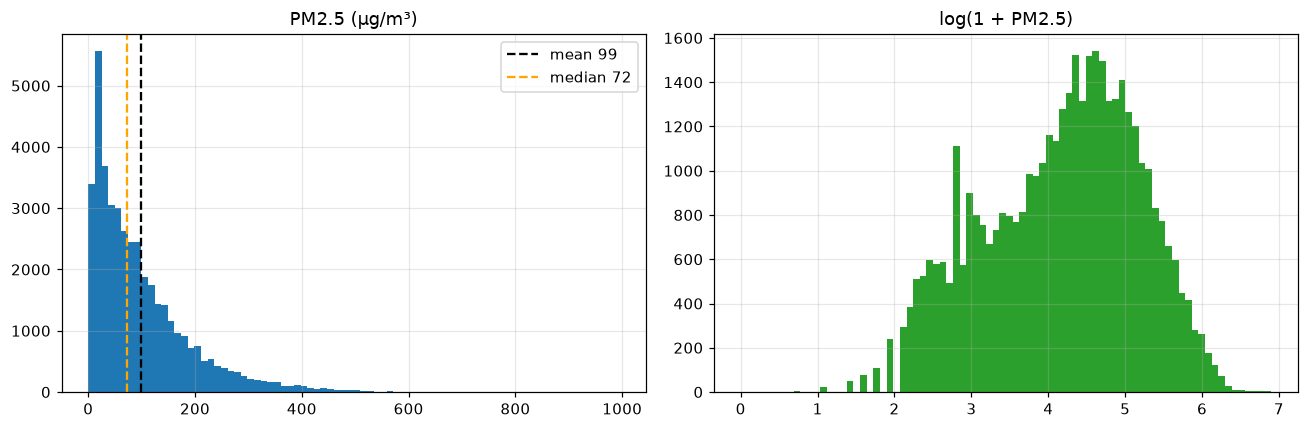

In [7]:
pm = raw["pm25"].dropna()
print("Mean:", round(pm.mean(), 1), "| Median:", pm.median(), "| Max:", pm.max(), "| Skew:", round(pm.skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(pm, bins=80, color="tab:blue")
axes[0].axvline(pm.mean(), color="black", linestyle="--", label=f"mean {pm.mean():.0f}")
axes[0].axvline(pm.median(), color="orange", linestyle="--", label=f"median {pm.median():.0f}")
axes[0].set_title("PM2.5 (µg/m³)")
axes[0].legend()
axes[1].hist(np.log1p(pm), bins=80, color="tab:green")
axes[1].set_title("log(1 + PM2.5)")
plt.tight_layout()
plt.savefig(f"{FIG}/02_pm25_distribution.png")
plt.show()

## Key findings

- **43,824 hourly rows**, 8 columns after building the datetime index.
- **Only PM2.5 is missing:** 2,067 hours (4.7%). Most gaps are in 2010 to 2012, and the longest gap is 155 hours in a row.
- PM2.5 is **strongly right-skewed** (skew about 1.8). The median is 72 but the maximum is 994 µg/m³, so a few extreme pollution episodes dominate RMSE.
- Because of the gaps, cleaning keeps a `pm25_missing` flag and fills gaps with forward fill only, and we never score a model on a filled value.